# Capstone Milestone One — Week 1: Polynomial and Interaction Terms

**Kumar Gaurav · DX799 O1 Data Science Capstone**

## Project Overview

Consumer credit risk is a central concern for lenders because mispriced loans and misjudged credit limits translate directly into losses and lost customers.

In this analysis, I use two consumer credit datasets to investigate how borrower characteristics relate to two risk-based lender decisions: the interest rate charged on an installment loan, and the credit limit granted on a revolving credit card.

### Research Question

Can borrower demographic, credit history, and repayment behavior be used to explain the risk-based prices and limits that lenders set?

The two target variables used here are:

* **Lending Club `int_rate`** — the interest rate (%) charged on an installment loan.
* **Taiwan `log(LIMIT_BAL)`** — the log of the credit limit granted on a revolving credit card.

### Objectives

The objectives of this analysis are to:

* Audit each dataset for missing values, duplicates, invalid ranges, and target leakage before any modeling.
* Fit linear regression models that include polynomial, interaction, and categorical terms.
* Diagnose multicollinearity using the Variance Inflation Factor (VIF) and show how centering changes the result.
* Compare models using training R², adjusted R², AIC, test RMSE, and partial F-tests.
* Interpret the resulting coefficients within the fitted linear model.

### Approach

The analysis follows a two-part structure:

Data Quality Audit → Lending Club Modeling → Taiwan Modeling → Summary

Each dataset is audited independently before any model is fit, so that cleaning decisions are documented and visible to the reader.

### Datasets

* **Lending Club** (Kaggle `adarshsng/lending-club-loan-data-csv`): US peer-to-peer installment loans, 2007–2018.
* **UCI Default of Credit Card Clients** (Yeh & Lien, 2009; Kaggle `uciml/default-of-credit-card-clients-dataset`): 30,000 Taiwanese credit-card clients, April–September 2005, with a target of default in October 2005.

## Part A — Data Quality Audit

Before fitting any model, I check the data in the way a careful analyst would by hand: what is in the file, what is missing, what is duplicated, which values are impossible, which columns would leak the answer, and what the target looks like.

Every issue identified is recorded in a data-quality summary table (issue, rows affected, action) so a reader can judge how much the cleaning might have influenced the modeling results.

### 1. Data Loading and Initial Setup

Everything that follows depends on reading the raw Lending Club file correctly. The file contains 145 columns and about 2.26 million rows, so instead of loading all of it I read only the subset of columns that will be audited or modeled.

A fixed random seed is set so that any sampling or splitting below is reproducible. Four columns known only *after* the loan outcome (`total_pymnt`, `recoveries`, `last_pymnt_amnt`, `out_prncp`) are loaded intentionally so that the leakage screen can later demonstrate why they must be removed.

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
SEED = 42

# Lending Club: read only the columns we audit/model (the raw file is 2.26M x 145)
LC_PATH = os.path.join(kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv/versions/1"), "loan.csv")
LC_COLS = ["id", "loan_status", "loan_amnt", "term", "int_rate", "grade", "sub_grade", "emp_length",
           "home_ownership", "annual_inc", "verification_status", "purpose", "dti", "delinq_2yrs",
           "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "mort_acc",
           "pub_rec_bankruptcies", "application_type", "policy_code",
           # post-outcome columns, loaded ONLY to demonstrate the leakage screen
           "total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]
lc_raw = pd.read_csv(LC_PATH, usecols=LC_COLS, low_memory=False)
print(f"Lending Club raw shape (audited columns): {lc_raw.shape}")
print(lc_raw.dtypes.value_counts().to_string())
display(lc_raw.head(3))

Lending Club raw shape (audited columns): (2260668, 28)
float64    16
str         9
int64       3


,id,loan_amnt,term,int_rate,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,...,revol_util,total_acc,out_prncp,total_pymnt,recoveries,last_pymnt_amnt,policy_code,application_type,mort_acc,pub_rec_bankruptcies
0,NaN,2500,36 months,13.56,C,C1,10+ years,RENT,55000.0,Not Verified,...,10.3,34.0,2386.02,167.02,0.0,84.92,1,Individual,0.0,1.0
1,NaN,30000,60 months,18.94,D,D2,10+ years,MORTGAGE,90000.0,Source Verified,...,24.2,44.0,29387.75,1507.11,0.0,777.23,1,Individual,3.0,1.0
2,NaN,5000,36 months,17.97,D,D1,6 years,MORTGAGE,59280.0,Source Verified,...,19.1,13.0,4787.21,353.89,0.0,180.69,1,Individual,2.0,0.0


### Load Findings

The audited subset loaded as 2,260,668 rows by 28 columns, with 16 float, 9 text, and 3 integer columns. The first three rows show plausible loan amounts between \$2,500 and \$30,000 and interest rates between 13.56% and 18.94%.

Two issues are already visible from the first rows. The `id` column is empty, and the `term` column contains a leading space (e.g., `" 36 months"`) that will need to be parsed. The non-zero values in `out_prncp` for the first rows reflect loans that are still *current*, which is handled by the censoring and leakage checks below.

### Missing Value Analysis

Missing data silently reduces or biases the sample. Columns that are mostly empty cannot be used, and columns that are entirely empty are useless — including identifier columns that might otherwise have been used to detect duplicates.

Because the raw file is too large to load fully into memory, the null count is accumulated across chunks of 500,000 rows. The missing percentage per column is then computed as the chunked count divided by total rows.

In [2]:
# Null audit on the FULL 145-column header (chunked so memory stays small)
null_cnt, n_rows = None, 0
for ch in pd.read_csv(LC_PATH, chunksize=500_000, low_memory=False):
    c = ch.isnull().sum(); null_cnt = c if null_cnt is None else null_cnt + c; n_rows += len(ch)
null_pct = (null_cnt / n_rows * 100).sort_values(ascending=False)
print(f"All columns: {len(null_pct)} | rows: {n_rows:,}")
print(f"Columns 100% empty: {(null_pct == 100).sum()} -> {null_pct[null_pct == 100].index.tolist()}")
print(f"Columns > 50% missing (dropped from consideration): {(null_pct > 50).sum()}")
print("\nMissing % for the columns we use:")
use_pct = null_pct.reindex([c for c in LC_COLS if c != "id"]).round(3)
print(use_pct[use_pct > 0].to_string())

All columns: 145 | rows: 2,260,668
Columns 100% empty: 3 -> ['id', 'url', 'member_id']
Columns > 50% missing (dropped from consideration): 44

Missing % for the columns we use:
emp_length              6.498
dti                     0.076
delinq_2yrs             0.001
inq_last_6mths          0.001
open_acc                0.001
pub_rec                 0.001
revol_util              0.080
total_acc               0.001
mort_acc                2.213
pub_rec_bankruptcies    0.060


### Missing Value Findings

Three of the 145 columns are entirely empty (`id`, `url`, `member_id`), and 44 columns are more than 50% missing. The latter group consists mostly of hardship, settlement, and joint-applicant fields that only apply to a small share of loans, and none of them are used in modeling.

Among the columns that will be used, missingness is small: `emp_length` 6.50%, `mort_acc` 2.21%, `revol_util` 0.080%, `dti` 0.076%, `pub_rec_bankruptcies` 0.060%, and the remainder about 0.001%.

Because missingness in the model columns is low, dropping incomplete rows removes only a small share of the data. `emp_length` is excluded from the models separately because its missingness may not be random — borrowers who leave the field blank may differ in risk from those who do not.

The fact that `id` is entirely empty means duplicates must be detected by comparing whole rows rather than by key.

### Cleaning Decisions — Outcomes, Duplicates, Invalid Values, and Leakage

A model will learn whatever is in the data, including errors. This step applies explicit, documented cleaning rules:

* **Outcome definition.** Only closed loans (`Fully Paid`, `Charged Off`, `Default`) have a known outcome. `Current` and late loans are censored, so including them would mislabel future defaults as repaid.
* **Duplicates.** Because `id` is empty in this Kaggle copy, duplicates are detected across whole rows.
* **Impossible values.** `dti` (debt-to-income) below 0 or above 100 (including the sentinel value 999) is treated as missing. Annual income of 0 is dropped because it breaks any log or ratio.
* **Extreme but possible values.** A `revol_util` above 100% means the borrower is over their credit limit. This is unusual but real, so values are clipped at 150 rather than dropped.
* **Rare categories.** `home_ownership` codes `ANY` and `NONE` are merged into `OTHER` so that one-hot encoding does not create near-empty columns.
* **Constant columns** carry no information and are dropped.
* **Leakage screen.** A column known only after the outcome (payments received, recoveries) would make the model look brilliant and be useless in practice. The mean of each post-outcome column is printed by outcome to show the leak before the columns are dropped.

Imputation (median or model-based) and winsorizing at percentiles are alternatives to the chosen listwise-drop and clipping rules. With under 1% of rows affected by any single check, listwise dropping is simpler and easier to defend.

In [3]:
# Keep closed loans only (outcome known); 'Current'/'Late' loans are censored
CLOSED = ["Fully Paid", "Charged Off", "Default"]
print("loan_status counts:"); print(lc_raw["loan_status"].value_counts().to_string())
lc = lc_raw[lc_raw["loan_status"].isin(CLOSED)].copy()
print(f"\nClosed loans: {len(lc):,}")

dq = []  # (issue, rows affected, action)
dq.append(("Open/censored loan_status", len(lc_raw) - len(lc), "dropped (outcome unknown)"))
dq.append(("id column 100% null", 0, "cannot dedupe on id; deduped on full row instead"))
dups = lc.drop(columns=["id"]).duplicated().sum(); dq.append(("Exact duplicate rows", dups, "dropped"))
lc = lc.drop(columns=["id"]).drop_duplicates()

# Invalid / impossible ranges
bad_dti = ((lc["dti"] < 0) | (lc["dti"] > 100)).sum()
dq.append(("dti < 0 or > 100% (sentinel 999 / data error)", bad_dti, "set to NaN then dropped"))
lc.loc[(lc["dti"] < 0) | (lc["dti"] > 100), "dti"] = np.nan
hi_util = (lc["revol_util"] > 100).sum()
dq.append(("revol_util > 100%", hi_util, "clipped to 150 (over-limit is real but extreme)"))
lc["revol_util"] = lc["revol_util"].clip(upper=150)
zero_inc = (lc["annual_inc"] <= 0).sum()
dq.append(("annual_inc <= 0", zero_inc, "dropped (cannot log/ratio)"))
lc = lc[lc["annual_inc"] > 0]
hi_inc = (lc["annual_inc"] > 1e6).sum()
dq.append(("annual_inc > $1M", hi_inc, "kept; modeled as log1p(annual_inc)"))
odd_home = lc["home_ownership"].isin(["ANY", "NONE", "OTHER"]).sum()
dq.append(("home_ownership ANY/NONE/OTHER", odd_home, "merged into OTHER"))
lc["home_ownership"] = lc["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})

# Constant / near-constant and cardinality
const = [c for c in lc.columns if lc[c].nunique(dropna=False) <= 1]
print("Constant columns:", const)
dq.append(("Constant columns " + str(const), 0, "column dropped (no information)"))
lc = lc.drop(columns=const)
cat_cols = lc.select_dtypes("object").columns
print("Categorical cardinality:", lc[cat_cols].nunique().to_dict())

# Leakage screen: columns only known AFTER the outcome
LEAK = ["total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]
print("\nLeakage check: mean of post-outcome columns by outcome")
print(lc.groupby(lc["loan_status"] != "Fully Paid")[LEAK].mean().round(1).rename(index={False: "repaid", True: "default"}).to_string())
dq.append(("Post-outcome columns " + ", ".join(LEAK), 0, "columns dropped (target leakage)"))
lc = lc.drop(columns=LEAK)

lc["default"] = (lc["loan_status"] != "Fully Paid").astype(int)
before = len(lc)
lc = lc.dropna(subset=["dti", "revol_util", "mort_acc", "pub_rec_bankruptcies", "inq_last_6mths", "open_acc", "total_acc"])
dq.append(("Remaining NaNs in model columns", before - len(lc), "dropped (listwise)"))
lc["log_annual_inc"] = np.log1p(lc["annual_inc"]); lc["log_revol_bal"] = np.log1p(lc["revol_bal"])
lc["term_months"] = lc["term"].str.extract(r"(\d+)").astype(int)
print(f"\nClean Lending Club rows: {len(lc):,} | default rate: {lc['default'].mean():.2%}")

loan_status counts:
loan_status
Fully Paid                                             1041952
Current                                                 919695
Charged Off                                             261655
Late (31-120 days)                                       21897
In Grace Period                                           8952
Late (16-30 days)                                         3737
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     31

Closed loans: 1,303,638
Constant columns: ['policy_code']
Categorical cardinality: {'term': 2, 'grade': 7, 'sub_grade': 35, 'emp_length': 11, 'home_ownership': 4, 'verification_status': 3, 'loan_status': 3, 'purpose': 14, 'application_type': 2}

Leakage check: mean of post-outcome columns by outcome
             total_pymnt  recoveries  last_pymnt_amnt  out_prncp
loan_status                       

### Cleaning Findings

Closed loans total 1,303,638, made up of 1,041,952 fully paid, 261,655 charged off, and 31 default. The 919,695 `Current` loans and the late or grace-period loans are excluded. One constant column (`policy_code`, always 1) is dropped. The remaining categorical variables have manageable cardinality: `sub_grade` has 35 levels and `purpose` has 14.

The leakage proof is striking. Repaid loans average \$16,439 in `total_pymnt` and \$0 in `recoveries`, while defaulted loans average \$8,228 and \$1,174 respectively. `recoveries` is non-zero only after a default, so a model given this column would effectively be reading the outcome. All four post-outcome columns are therefore dropped.

After all cleaning, 1,254,818 closed loans remain, with a 20.28% default rate.

### Data Quality Summary and Target Distribution

The data-quality summary table consolidates every cleaning decision taken above. The target balance, the distribution of key numerical features, and the effect of the log transform on income are reviewed together, because an imbalanced target changes how model performance should be judged and heavy skew justifies the log transformation.

,issue,rows_affected,action
0,Open/censored loan_status,957030,dropped (outcome unknown)
1,id column 100% null,0,cannot dedupe on id; deduped on full row instead
2,Exact duplicate rows,0,dropped
3,dti < 0 or > 100% (sentinel 999 / data error),478,set to NaN then dropped
4,revol_util > 100%,4537,clipped to 150 (over-limit is real but extreme)
5,annual_inc <= 0,302,dropped (cannot log/ratio)
6,annual_inc > $1M,279,kept; modeled as log1p(annual_inc)
7,home_ownership ANY/NONE/OTHER,459,merged into OTHER
8,Constant columns ['policy_code'],0,column dropped (no information)
9,"Post-outcome columns total_pymnt, recoveries, ...",0,columns dropped (target leakage)


,count,mean,std,min,25%,50%,75%,max
loan_amnt,1254818.0,14521.03,8716.03,1000.00,8000.00,12000.00,20000.00,40000.00
int_rate,1254818.0,13.30,4.79,5.31,9.75,12.79,16.02,30.99
annual_inc,1254818.0,76459.53,70288.00,430.00,46000.00,65000.00,90000.00,10999200.00
dti,1254818.0,18.35,8.67,0.00,11.95,17.78,24.26,100.00
revol_util,1254818.0,51.98,24.34,0.00,33.80,52.30,70.70,150.00
open_acc,1254818.0,11.68,5.48,1.00,8.00,11.00,14.00,90.00


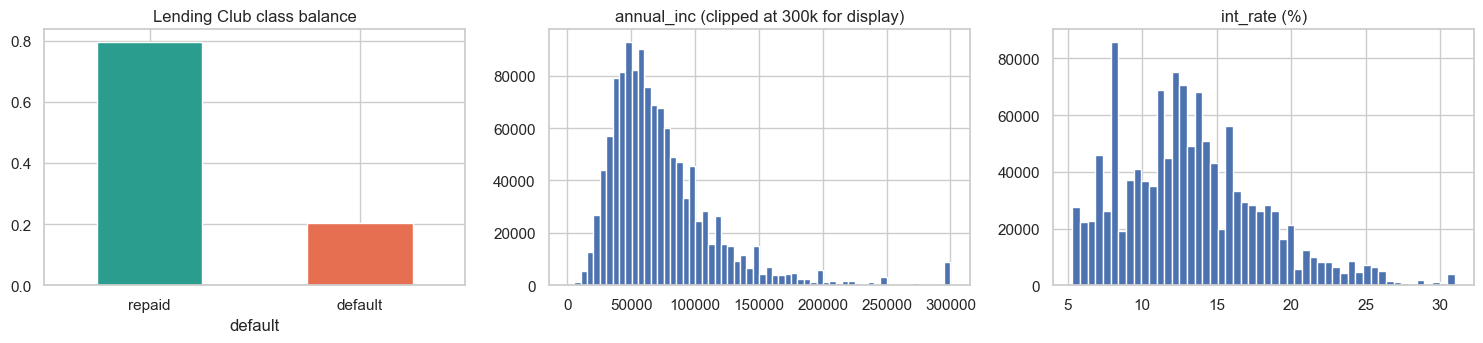

Skew annual_inc raw vs log1p: 47.64 -> 0.21


In [4]:
lc_dq = pd.DataFrame(dq, columns=["issue", "rows_affected", "action"])
display(lc_dq)
display(lc[["loan_amnt", "int_rate", "annual_inc", "dti", "revol_util", "open_acc"]].describe().round(2).T)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
lc["default"].value_counts(normalize=True).sort_index().plot.bar(ax=ax[0], color=["#2a9d8f", "#e76f51"])
ax[0].set_title("Lending Club class balance"); ax[0].set_xticklabels(["repaid", "default"], rotation=0)
ax[1].hist(lc["annual_inc"].clip(upper=300000), bins=60); ax[1].set_title("annual_inc (clipped at 300k for display)")
ax[2].hist(lc["int_rate"], bins=50); ax[2].set_title("int_rate (%)")
plt.tight_layout(); plt.show()
print("Skew annual_inc raw vs log1p:", round(lc["annual_inc"].skew(), 2), "->", round(lc["log_annual_inc"].skew(), 2))

### Data Quality Summary Findings

The summary table reports the following cleaning impacts:

| Issue | Rows affected | Share of closed loans |
|---|---|---|
| Open or censored status | 957,030 | dropped before the closed count |
| `dti` < 0 or > 100 | 478 | 0.04% |
| `revol_util` > 100% | 4,537 | 0.35% (clipped at 150) |
| `annual_inc` ≤ 0 | 302 | 0.02% |
| `annual_inc` > \$1M | 279 | kept, log-transformed |
| `home_ownership` ANY/NONE/OTHER | 459 | merged |
| Remaining NaNs | 48,518 | 3.7% (mostly `mort_acc`) |

No exact duplicate rows were found. After cleaning, `int_rate` has a mean of 13.30% with a standard deviation of 4.79 and a range of 5.31 to 30.99. `annual_inc` has a mean of \$76,437, a median of \$65,000, and a maximum of nearly \$11M. Its raw skew of 47.64 falls to 0.21 after the `log1p` transform. The class-balance plot shows approximately 80/20 repaid versus default.

Two conclusions follow. First, income must be modeled on the log scale; without it, a few very high incomes would dominate any linear fit. Second, accuracy is a weak metric for this target because an "everyone repays" rule already scores about 80%, so classification work on this dataset needs ROC-AUC, F1, and recall rather than accuracy alone.

### 2. Taiwan Credit Card Data — Loading

The Taiwan Default of Credit Card Clients dataset provides a second view of consumer credit risk. The market is different (revolving credit cards in Taiwan 2005 rather than installment loans in the US), but the underlying question — who will default — is the same, so it allows a check on whether conclusions generalize beyond Lending Club.

The columns include `LIMIT_BAL` (credit limit, in NT\$), demographics (`SEX`, `EDUCATION`, `MARRIAGE`, `AGE`), monthly repayment status (`PAY_0`, `PAY_2`..`PAY_6`, where −1 means paid on time and 1..9 means months late), monthly statement balances (`BILL_AMT1-6`), payments made (`PAY_AMT1-6`), and the target `default.payment.next.month`.

In [5]:
TW_PATH = os.path.join(kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset/versions/1"), "UCI_Credit_Card.csv")
tw_raw = pd.read_csv(TW_PATH)
print(f"Taiwan raw shape: {tw_raw.shape}")
print(tw_raw.dtypes.value_counts().to_string())
display(tw_raw.head(3))

Taiwan raw shape: (30000, 25)
float64    13
int64      12


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0


### Taiwan Load Findings

The file loaded as 30,000 rows by 25 columns, with 13 float and 12 integer columns and no text columns. In the first row, `PAY_0` is 2 (two months late) and the target is 1, which is an early hint that repayment status carries a strong signal.

### Taiwan Data Quality — Undocumented Codes, Duplicates, and Transformations

The Taiwan dataset is well known for containing undocumented category codes: `EDUCATION` values of 0, 5, and 6, a `MARRIAGE` value of 0, and `PAY_*` values of −2. Left as-is, a model would treat these as meaningful categories. The cleaning here applies several decisions:

* `PAY_0` is renamed to `PAY_1` so that the six monthly columns are numbered consistently, and the long target name is renamed to `default`.
* Duplicate detection ignores `ID`, since different IDs with identical 23 features are almost certainly repeated records.
* Undocumented category codes are merged into the documented "other" category.
* `PAY_*` is kept as an ordinal numeric variable (−2 < −1 < 0 < 1 < … months late), because the ordering carries risk information.
* Negative bill amounts (which represent customer overpayments) are real and are preserved via a signed log transform `sign(x)·log(1 + |x|)` that tames skew while keeping the sign.

In [6]:
tw = tw_raw.rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"}).copy()
PAY = [f"PAY_{i}" for i in range(1, 7)]; BILL = [f"BILL_AMT{i}" for i in range(1, 7)]; PAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
tdq = []
print("Null cells total:", int(tw.isnull().sum().sum()))
tdq.append(("Missing values", int(tw.isnull().sum().sum()), "none to handle"))
tdq.append(("Duplicate ID", int(tw["ID"].duplicated().sum()), "none"))
dup = int(tw.drop(columns="ID").duplicated().sum())
tdq.append(("Duplicate rows (ignoring ID)", dup, "dropped (identical profiles)"))
tw = tw.loc[~tw.drop(columns="ID").duplicated()].copy()

print("EDUCATION codes:", tw["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE codes:", tw["MARRIAGE"].value_counts().sort_index().to_dict())
print("PAY_1 codes:", tw["PAY_1"].value_counts().sort_index().to_dict())
edu_bad = int(tw["EDUCATION"].isin([0, 5, 6]).sum())
tdq.append(("EDUCATION undocumented codes 0/5/6", edu_bad, "recoded to 4 = other"))
tw["EDUCATION"] = tw["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
mar_bad = int((tw["MARRIAGE"] == 0).sum())
tdq.append(("MARRIAGE undocumented code 0", mar_bad, "recoded to 3 = other"))
tw["MARRIAGE"] = tw["MARRIAGE"].replace({0: 3})
pay_m2 = int((tw[PAY] == -2).any(axis=1).sum())
tdq.append(("PAY_* = -2 (no consumption, undocumented)", pay_m2, "kept as ordinal (-2 < -1 paid duly < 0 revolving)"))
neg_bill = int((tw[BILL] < 0).any(axis=1).sum())
tdq.append(("Negative BILL_AMT (credit balance/overpay)", neg_bill, "kept; signed log transform"))
tdq.append(("AGE range " + f"{tw['AGE'].min()}-{tw['AGE'].max()}", 0, "plausible, kept"))
const = [c for c in tw.columns if tw[c].nunique() <= 1]; tdq.append(("Constant columns", len(const), "none"))

# Leakage screen: all features are observed BEFORE the default month (Apr-Sep 2005 -> Oct 2005)
tdq.append(("Post-outcome columns", 0, "none: all features precede target month"))
slog = lambda s: np.sign(s) * np.log1p(np.abs(s))
for c in BILL + PAMT: tw["log_" + c] = slog(tw[c])
tw["log_LIMIT_BAL"] = np.log(tw["LIMIT_BAL"])
tw = tw.drop(columns="ID")
print(f"\nClean Taiwan rows: {len(tw):,} | default rate: {tw['default'].mean():.2%}")

Null cells total: 0
EDUCATION codes: {0: 14, 1: 10563, 2: 14019, 3: 4915, 4: 123, 5: 280, 6: 51}
MARRIAGE codes: {0: 54, 1: 13643, 2: 15945, 3: 323}
PAY_1 codes: {-2: 2750, -1: 5682, 0: 14737, 1: 3667, 2: 2666, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}

Clean Taiwan rows: 29,965 | default rate: 22.13%


### Taiwan Cleaning Findings

The data contains no missing cells and no duplicate IDs, but 35 duplicate profiles are found when `ID` is ignored, and these rows are dropped.

The undocumented category counts are:

* `EDUCATION`: codes 0, 5, and 6 together account for 345 rows (0 → 14 rows, 5 → 280, 6 → 51).
* `MARRIAGE`: code 0 accounts for 54 rows.
* `PAY_1`: code −2 accounts for 2,750 rows, with a long tail of codes 3–8 that are each rare (322 rows or fewer).

The `EDUCATION` and `MARRIAGE` recodes affect roughly 1.3% of rows, so merging them into "other" is a low-risk choice. The `PAY_* = −2` code is far too common to drop; interpreting it as "no balance to pay" (ranked below "paid duly") is more defensible than treating it as missing.

After cleaning, 29,965 rows remain, with a 22.13% default rate.

### Taiwan Data Quality Summary, Collinearity Preview, and Target Balance

The summary table documents all Taiwan cleaning decisions. Two preview visualizations are added:

* A correlation heatmap of the six monthly bill columns, to show whether multicollinearity among the bills is likely to matter.
* The default rate by `PAY_1`, to preview the strongest expected risk signal.

The skew of `LIMIT_BAL` is also checked before and after a log transform, since the target for the Taiwan modeling will be `log(LIMIT_BAL)`.

,issue,rows_affected,action
0,Missing values,0,none to handle
1,Duplicate ID,0,none
2,Duplicate rows (ignoring ID),35,dropped (identical profiles)
3,EDUCATION undocumented codes 0/5/6,345,recoded to 4 = other
4,MARRIAGE undocumented code 0,54,recoded to 3 = other
5,"PAY_* = -2 (no consumption, undocumented)",6531,kept as ordinal (-2 < -1 paid duly < 0 revolving)
6,Negative BILL_AMT (credit balance/overpay),1930,kept; signed log transform
7,AGE range 21-79,0,"plausible, kept"
8,Constant columns,0,none
9,Post-outcome columns,0,none: all features precede target month


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,29965.0,167442.0,129760.1,10000.0,50000.0,140000.0,240000.0,1000000.0
AGE,29965.0,35.5,9.2,21.0,28.0,34.0,41.0,79.0
BILL_AMT1,29965.0,51283.0,73658.1,-165580.0,3595.0,22438.0,67260.0,964511.0
PAY_AMT1,29965.0,5670.1,16571.8,0.0,1000.0,2102.0,5008.0,873552.0
PAY_1,29965.0,-0.0,1.1,-2.0,-1.0,0.0,0.0,8.0


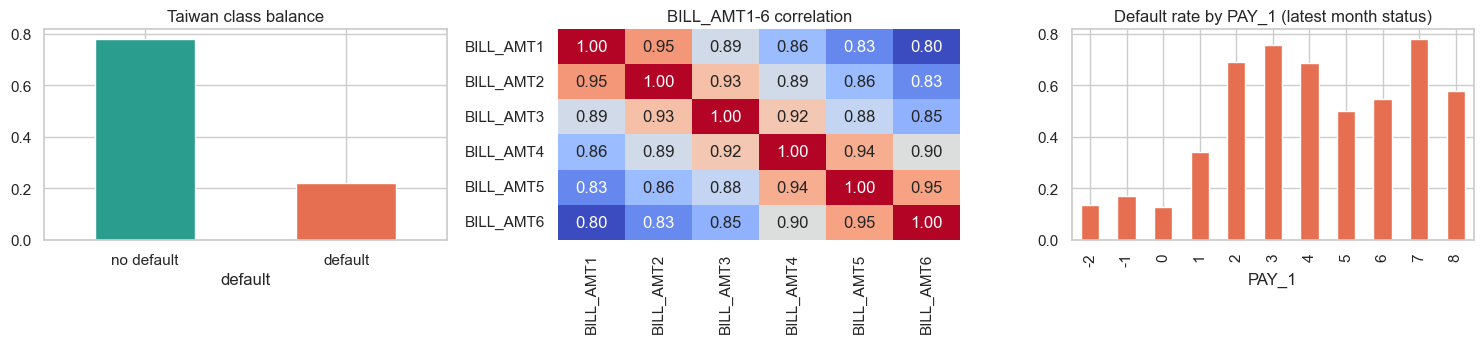

Skew LIMIT_BAL raw vs log: 0.99 -> -0.51


In [7]:
tw_dq = pd.DataFrame(tdq, columns=["issue", "rows_affected", "action"])
display(tw_dq)
display(tw[["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "PAY_1"]].describe().round(1).T)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
tw["default"].value_counts(normalize=True).sort_index().plot.bar(ax=ax[0], color=["#2a9d8f", "#e76f51"])
ax[0].set_title("Taiwan class balance"); ax[0].set_xticklabels(["no default", "default"], rotation=0)
sns.heatmap(tw[BILL].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1], cbar=False)
ax[1].set_title("BILL_AMT1-6 correlation")
tw.groupby("PAY_1")["default"].mean().plot.bar(ax=ax[2], color="#e76f51"); ax[2].set_title("Default rate by PAY_1 (latest month status)")
plt.tight_layout(); plt.show()
print("Skew LIMIT_BAL raw vs log:", round(tw["LIMIT_BAL"].skew(), 2), "->", round(tw["log_LIMIT_BAL"].skew(), 2))

### Taiwan Summary Findings

The issues table records 35 duplicates, 345 education recodes, 54 marriage recodes, 6,531 rows containing a −2 code in some month, and 1,930 rows with a negative bill. Ages run 21 to 79. No leakage columns are present because all features are observed in April–September 2005 while the target is default in October 2005.

The bill correlations are high. Neighbouring months of `BILL_AMT` have correlations near 0.95, and month 1 versus month 6 is still about 0.80. This is the hallmark of multicollinearity.

The default rate rises sharply with `PAY_1`. Rates sit between 13% and 17% for codes −2, −1, and 0 (no balance, paid duly, revolving), rise to about 34% for one month late and 69% for two months late, and remain between 50% and 78% for the rarer longer delays. `PAY_1` is clearly the dominant risk signal in this dataset.

`LIMIT_BAL` has a raw skew of 0.99, which falls to −0.51 after the log transform. The log scale is therefore used as the modeling target. The default rate of 22% is close to Lending Club's 20%, so the same metric considerations apply.

## Part B — Linear Regression with Polynomial and Interaction Terms

With both datasets cleaned, the modeling focuses on three questions:

* Does the relationship between a numeric predictor and the target bend (polynomial)?
* Does the slope of one predictor depend on another (interaction)?
* How much does a categorical variable (e.g., Lending Club `grade`, Taiwan `PAY_1`) add on top of continuous predictors?

### Hypotheses

The hypotheses tested throughout the modeling are:

* **For each coefficient.** H₀: β = 0 (no linear association, holding the other predictors fixed) vs H₁: β ≠ 0, at α = 0.05.
* **For each nested model comparison** (adding squared or interaction terms, or switching a variable from continuous to categorical). H₀: the added terms add no explanatory power vs H₁: at least one added term is non-zero. A partial F-test provides the decision.

### 3. Lending Club Modeling — Sample and Train/Test Split

OLS on 1.3 million rows makes every coefficient "significant" through tiny standard errors, which hides practical importance. A reproducible 25,000-loan sample is large enough for stable estimates while keeping p-values meaningful. An 80/20 split provides an honest test RMSE, because R² on the training data mechanically improves whenever terms are added.

The predictors used are all known at application time: `loan_amnt`, `log_annual_inc`, `dti`, `revol_util`, `inq_last_6mths`, `open_acc`, `total_acc`, `mort_acc`, and the categorical `term` (36 vs 60 months).

Centering (subtracting the training mean) is applied to any variable that will later be squared or multiplied by another. The mean is computed on the training data only to avoid data leakage.

The reason to center before squaring is purely numerical. `revol_util` (range 0 to 150) and `revol_util²` (range 0 to 22,500) rise together almost perfectly and are therefore highly collinear. After centering, the squared term measures distance from the average, which is far less correlated with the linear term. The fit is unchanged; only the coefficient standard errors become trustworthy.

In [8]:
import statsmodels.api as sm, statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.anova import anova_lm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

LC_NUM = ["loan_amnt", "log_annual_inc", "dti", "revol_util", "inq_last_6mths", "open_acc", "total_acc", "mort_acc"]
lc_reg = lc[LC_NUM + ["term", "grade", "int_rate"]].sample(n=25_000, random_state=SEED)
lc_tr, lc_te = train_test_split(lc_reg, test_size=0.2, random_state=SEED)
lc_tr, lc_te = lc_tr.copy(), lc_te.copy()
for c in ["dti", "revol_util", "log_annual_inc"]:
    mu = lc_tr[c].mean()
    lc_tr[c + "_c"] = lc_tr[c] - mu; lc_te[c + "_c"] = lc_te[c] - mu
print(f"Train {lc_tr.shape}, Test {lc_te.shape}")
print(lc_tr["int_rate"].describe().round(3).to_string())

Train (20000, 14), Test (5000, 14)
count    20000.000
mean        13.301
std          4.762
min          5.310
25%          9.800
50%         12.740
75%         16.020
max         30.990


### Sample Findings

The sampling produced a training set of 20,000 by 14 and a test set of 5,000 by 14. In the training set, `int_rate` has a mean of 13.30%, a standard deviation of 4.79, a median of 12.79, and a range of 5.31 to 30.99.

The 4.79 standard deviation is the RMSE a model would achieve by always predicting the mean, so later test RMSE values should be compared against 4.79. The sample mean matches the full cleaned population mean of 13.30%, which indicates that the random sample is representative.

### 4. Lending Club — Nested Models (Base, Polynomial, Interaction, Categorical)

Four nested OLS models are fit via `statsmodels` formula syntax. The notation `C(term)` treats `term` as categorical and creates one dummy with the reference level dropped (avoiding the dummy-variable trap).

* **M1 base.** All continuous predictors plus `C(term)`.
* **M2 + polynomial.** Adds `I(revol_util_c**2)` and `I(dti_c**2)`.
* **M3 + interaction.** Adds `dti_c:revol_util_c` (does high debt load matter more when utilization is high?) and `log_annual_inc_c:C(term)`.
* **M4 + categorical grade.** Adds `C(grade)` (A is the reference level). Grade is Lending Club's own risk rating, so this quantifies how much of the price is set by that rating.

For each model, train R², adjusted R², AIC, test RMSE, and the condition number are reported. The partial F-test from `anova_lm` tests each successive model against the previous one.

As an alternative, `sklearn.PolynomialFeatures` could be used to generate all squares and pairwise products automatically. That approach is useful for pure prediction but much harder to interpret. Splines or GAMs would offer smooth curves at the cost of linear-model interpretability.

In [9]:
f1 = "int_rate ~ loan_amnt + log_annual_inc_c + dti_c + revol_util_c + inq_last_6mths + open_acc + total_acc + mort_acc + C(term)"
f2 = f1 + " + I(revol_util_c**2) + I(dti_c**2)"
f3 = f2 + " + dti_c:revol_util_c + log_annual_inc_c:C(term)"
f4 = f3 + " + C(grade)"
lc_models = {name: smf.ols(f, data=lc_tr).fit() for name, f in
             [("M1 base", f1), ("M2 +poly", f2), ("M3 +interaction", f3), ("M4 +grade (categorical)", f4)]}
rows = []
for name, m in lc_models.items():
    rmse = np.sqrt(mean_squared_error(lc_te["int_rate"], m.predict(lc_te)))
    rows.append([name, int(m.df_model), m.rsquared, m.rsquared_adj, m.aic, rmse, m.condition_number])
lc_w1 = pd.DataFrame(rows, columns=["model", "df_model", "R2_train", "adjR2", "AIC", "RMSE_test", "cond_no"])
display(lc_w1.round(4))
print("Partial F-tests (each model vs the previous one):")
display(anova_lm(*lc_models.values()).round(4))
m3 = lc_models["M3 +interaction"]
terms = ["I(revol_util_c ** 2)", "I(dti_c ** 2)", "dti_c:revol_util_c", "log_annual_inc_c:C(term)[T. 60 months]", "revol_util_c", "dti_c"]
display(pd.DataFrame({"coef": m3.params, "std_err": m3.bse, "t": m3.tvalues, "p": m3.pvalues,
                      "ci_low": m3.conf_int()[0], "ci_high": m3.conf_int()[1]}).loc[[t for t in terms if t in m3.params.index]].round(5))

,model,df_model,R2_train,adjR2,AIC,RMSE_test,cond_no
0,M1 base,9,0.3227,0.3224,111410.7363,3.9377,64839.9851
1,M2 +poly,11,0.3238,0.3234,111382.8848,3.9316,68927.7677
2,M3 +interaction,13,0.3240,0.3235,111381.4275,3.9320,86139.8899
3,M4 +grade (categorical),19,0.9139,0.9138,70181.3829,1.4256,221732.7328


Partial F-tests (each model vs the previous one):


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,19990.0,307167.1384,0.0,NaN,NaN,NaN
1,19988.0,306678.3402,2.0,488.7981,125.0370,0.0
2,19986.0,306594.6703,2.0,83.6699,21.4032,0.0
3,19980.0,39053.1817,6.0,267541.4886,22812.8188,0.0


,coef,std_err,t,p,ci_low,ci_high
I(revol_util_c ** 2),0.00007,0.00004,1.50184,0.13315,-0.00002,0.00015
I(dti_c ** 2),0.00114,0.00023,4.93442,0.00000,0.00069,0.00160
dti_c:revol_util_c,0.00019,0.00013,1.37209,0.17005,-0.00008,0.00045
log_annual_inc_c:C(term)[T. 60 months],0.26140,0.13786,1.89609,0.05796,-0.00882,0.53161
revol_util_c,0.04489,0.00122,36.70221,0.00000,0.04249,0.04728
dti_c,0.03967,0.00391,10.14558,0.00000,0.03200,0.04733


### Nested Model Findings

| Model | df | adj R² | AIC | Test RMSE |
|---|---|---|---|---|
| M1 base | 9 | 0.3224 | 111,410.7 | 3.9377 |
| M2 + squares | 11 | 0.3234 | 111,382.9 | 3.9316 |
| M3 + interactions | 13 | 0.3235 | 111,381.4 | 3.9320 |
| M4 + categorical grade | 19 | **0.9138** | **70,181.4** | **1.4256** |

The partial F-tests reject H₀ at every step:

* M1 → M2: F = 125.0, p < 0.001. The squared terms add explanatory power.
* M2 → M3: F = 21.4, p < 0.001. The interaction terms add explanatory power jointly.
* M3 → M4: F = 22,812.8, p < 0.001. Grade adds a large amount.

In M3, the individual term results are mixed:

* `dti_c²`: +0.00114, p < 0.001. Significant and positive; the rate rises faster at high debt-to-income.
* `revol_util_c²`: p = 0.133. Fail to reject H₀. No evidence of curvature in utilization.
* `dti_c × revol_util_c`: p = 0.170. Fail to reject H₀. The utilization slope does not vary with dti.
* `log_annual_inc_c × 60-month term`: p = 0.058. Borderline.
* Linear effects: +0.0449 interest-rate points per utilization point, and +0.0397 per dti point.

Two interpretive points matter. First, statistical significance and practical importance are not the same. With 20,000 rows, the squared terms are significant, but the test RMSE barely moves (3.9377 → 3.9316, a 0.006-point improvement on a 5–31% scale). The curvature is real but too small to matter in practice.

Second, grade dominates the price. Adding `C(grade)` lifts adjusted R² from 0.32 to 0.91 and cuts RMSE by 64%. Lending Club sets the rate mainly from its own grade, so the continuous borrower features mostly explain the price *through* the grade. This is a reporting fact about the pricing rule, not a causal statement about borrower behavior.

The condition number of about 221,733 for M4 is large but reflects the fact that raw features are on very different scales (`loan_amnt` is in dollars), not inflated collinearity. The VIF step below checks that directly.

### 5. Multicollinearity — VIF with Raw vs Centered Polynomial Terms

The Variance Inflation Factor measures how much a coefficient's variance is inflated because that predictor can be predicted from the others:

VIF = 1 / (1 − R²ⱼ)

A VIF greater than 5 is worth checking and a VIF greater than 10 is a serious concern, though both are rules of thumb rather than hard thresholds. Polynomial and interaction terms create collinearity by construction, and this step quantifies that and shows that centering removes most of it.

In [10]:
def vif_table(X):
    X = sm.add_constant(X.astype(float))
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=X.columns[1:])

raw = pd.DataFrame({"revol_util": lc_tr["revol_util"], "revol_util_sq": lc_tr["revol_util"]**2,
                    "dti": lc_tr["dti"], "dti_sq": lc_tr["dti"]**2, "dti_x_util": lc_tr["dti"]*lc_tr["revol_util"]})
cen = pd.DataFrame({"revol_util": lc_tr["revol_util_c"], "revol_util_sq": lc_tr["revol_util_c"]**2,
                    "dti": lc_tr["dti_c"], "dti_sq": lc_tr["dti_c"]**2, "dti_x_util": lc_tr["dti_c"]*lc_tr["revol_util_c"]})
vif_cmp = pd.DataFrame({"VIF_raw": vif_table(raw), "VIF_centered": vif_table(cen)}).round(2)
display(vif_cmp)
print("Condition number raw:", f"{np.linalg.cond(sm.add_constant(raw).values):.3g}",
      "| centered:", f"{np.linalg.cond(sm.add_constant(cen).values):.3g}")

,VIF_raw,VIF_centered
revol_util,17.64,1.04
revol_util_sq,16.39,1.06
dti,11.72,1.14
dti_sq,9.56,1.14
dti_x_util,11.58,1.10


Condition number raw: 2.47e+04 | centered: 1.3e+03


### VIF Findings

| Term | VIF raw | VIF centered |
|---|---|---|
| revol_util | 17.64 | 1.04 |
| revol_util² | 16.39 | 1.06 |
| dti | 11.72 | 1.14 |
| dti² | 9.56 | 1.14 |
| dti × util | 11.58 | 1.10 |

The condition number of the design matrix falls from about 24,700 raw to about 1,300 after centering.

The collinearity in the raw formulation is structural. Building `x²` and `x·z` from uncentered variables mechanically correlates them with `x` and `z`. Centering removes the problem, dropping every VIF to roughly 1.1 and the condition number by about 19-fold. Model predictions are unchanged; what changes is that the coefficient standard errors become trustworthy.

The practical lesson is that a high VIF on a polynomial term is not, by itself, a reason to drop the term. Center the inputs first, then judge.

### 6. Visualizing the Curvature and the Interaction

Squared and product coefficients are not easy to read directly. Plotting predicted `int_rate` across `revol_util` while holding other variables at their means shows the curve directly, and drawing one line per `dti` level shows whether the slope changes (the interaction).

A second panel compares actual vs predicted `int_rate` for M4, to show visually how adding the categorical grade reshapes the fit.

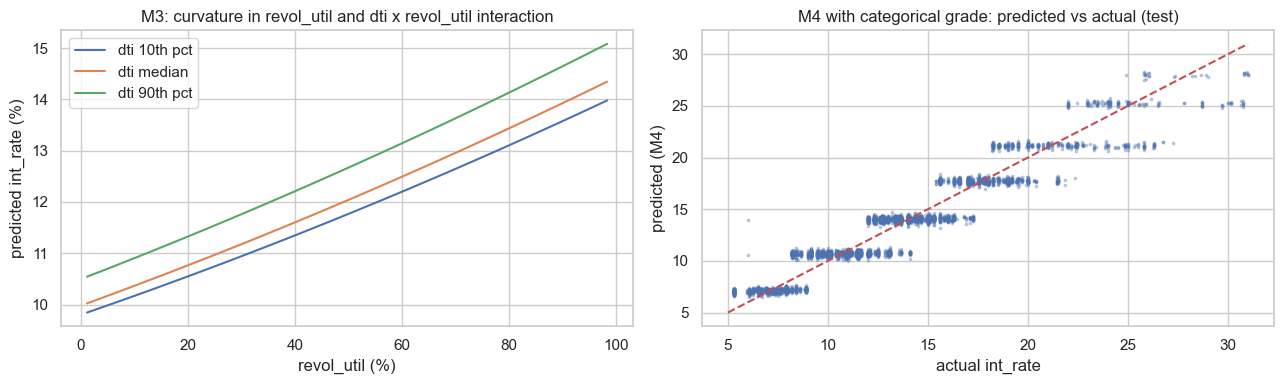

In [11]:
grid = pd.DataFrame({"revol_util_c": np.linspace(lc_tr["revol_util_c"].quantile(.01), lc_tr["revol_util_c"].quantile(.99), 100)})
base_row = {c: lc_tr[c].mean() for c in ["loan_amnt", "log_annual_inc_c", "inq_last_6mths", "open_acc", "total_acc", "mort_acc"]}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for label, q in [("dti 10th pct", .1), ("dti median", .5), ("dti 90th pct", .9)]:
    g = grid.assign(**base_row, dti_c=lc_tr["dti_c"].quantile(q), term=" 36 months")
    ax[0].plot(g["revol_util_c"] + lc_tr["revol_util"].mean(), m3.predict(g), label=label)
ax[0].set_xlabel("revol_util (%)"); ax[0].set_ylabel("predicted int_rate (%)"); ax[0].legend()
ax[0].set_title("M3: curvature in revol_util and dti x revol_util interaction")
ax[1].scatter(lc_te["int_rate"], lc_models["M4 +grade (categorical)"].predict(lc_te), s=3, alpha=.3)
ax[1].plot([5, 31], [5, 31], "r--"); ax[1].set_xlabel("actual int_rate"); ax[1].set_ylabel("predicted (M4)")
ax[1].set_title("M4 with categorical grade: predicted vs actual (test)")
plt.tight_layout(); plt.show()

### Visualization Findings

In the left panel, the predicted `int_rate` rises almost linearly with `revol_util`, and the three `dti` lines (10th percentile, median, 90th percentile) are nearly parallel and vertically shifted. Parallel lines are the visual signature of no interaction, which matches the non-significant p-value for `dti × revol_util` (p = 0.170). Debt load shifts the price level but does not change the utilization slope. The absence of visible bending in the utilization curve also matches the non-significant p-value for its square (p = 0.133).

In the right panel, the M4 predictions hug the diagonal in horizontal bands, with one band per grade. This banding is the signature of a categorical driver — within a band, the remaining error is the sub-grade and term variation that the model does not resolve.

### 7. Taiwan — Credit Limit with Polynomial Age, Age × Education Interaction, and PAY_1 as Continuous vs Categorical

The modeling target for Taiwan is `log(LIMIT_BAL)`, because credit limits are right-skewed and a coefficient on the log scale can be read as an approximate percentage change in the limit.

Three modeling questions are tested:

* Does `LIMIT_BAL` rise with age and then flatten (**polynomial** curvature)?
* Does the age effect differ by education (**interaction**)?
* Is the latest repayment status `PAY_1` better captured as a continuous ordinal variable (one slope) or as a categorical variable (one effect per code)?

Four OLS models are fit on an 80/20 split, with the same reporting metrics used for Lending Club.

In [12]:
tw_tr, tw_te = train_test_split(tw, test_size=0.2, random_state=SEED, stratify=tw["default"])
tw_tr, tw_te = tw_tr.copy(), tw_te.copy()
age_mu = tw_tr["AGE"].mean(); tw_tr["AGE_c"] = tw_tr["AGE"] - age_mu; tw_te["AGE_c"] = tw_te["AGE"] - age_mu
g1 = "log_LIMIT_BAL ~ AGE_c + C(SEX) + C(EDUCATION) + C(MARRIAGE) + PAY_1 + log_BILL_AMT1 + log_PAY_AMT1"
g2 = g1 + " + I(AGE_c**2)"
g3 = g2 + " + AGE_c:C(EDUCATION)"
g4 = g3.replace("PAY_1", "C(PAY_1)")
tw_models = {n: smf.ols(f, data=tw_tr).fit() for n, f in
             [("T1 base (PAY_1 continuous)", g1), ("T2 +AGE^2", g2), ("T3 +AGE x EDUCATION", g3), ("T4 PAY_1 categorical", g4)]}
rows = []
for name, m in tw_models.items():
    rmse = np.sqrt(mean_squared_error(tw_te["log_LIMIT_BAL"], m.predict(tw_te)))
    rows.append([name, int(m.df_model), m.rsquared, m.rsquared_adj, m.aic, rmse, m.condition_number])
tw_w1 = pd.DataFrame(rows, columns=["model", "df_model", "R2_train", "adjR2", "AIC", "RMSE_test(log)", "cond_no"])
display(tw_w1.round(4))
print("Partial F-tests T1 -> T2 -> T3 -> T4:")
display(anova_lm(*tw_models.values()).round(4))
t3 = tw_models["T3 +AGE x EDUCATION"]
keep = [k for k in t3.params.index if "AGE" in k or k == "PAY_1"]
display(pd.DataFrame({"coef": t3.params, "p": t3.pvalues, "ci_low": t3.conf_int()[0], "ci_high": t3.conf_int()[1]}).loc[keep].round(5))
peak = age_mu - t3.params["AGE_c"] / (2 * t3.params["I(AGE_c ** 2)"])
print(f"Implied age at which predicted limit peaks (reference education): {peak:.1f} years")

,model,df_model,R2_train,adjR2,AIC,RMSE_test(log),cond_no
0,T1 base (PAY_1 continuous),10,0.1876,0.1873,60270.5680,0.8387,106.5602
1,T2 +AGE^2,11,0.2241,0.2238,59169.4165,0.8222,1318.4031
2,T3 +AGE x EDUCATION,14,0.2309,0.2305,58965.6406,0.8194,1319.0172
3,T4 PAY_1 categorical,23,0.2415,0.2407,58652.1332,0.8133,8126.2828


Partial F-tests T1 -> T2 -> T3 -> T4:


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,23961.0,17327.5650,0.0,NaN,NaN,NaN
1,23960.0,16548.2483,1.0,779.3167,1153.5529,0.0
2,23957.0,16404.0685,3.0,144.1798,71.1388,0.0
3,23948.0,16178.7789,9.0,225.2895,37.0529,0.0


,coef,p,ci_low,ci_high
C(MARRIAGE)[T.2],-0.04961,0.00009,-0.07444,-0.02479
C(MARRIAGE)[T.3],-0.49948,0.00000,-0.59287,-0.40610
AGE_c,0.04274,0.00000,0.04030,0.04517
AGE_c:C(EDUCATION)[T.2],-0.01930,0.00000,-0.02206,-0.01653
AGE_c:C(EDUCATION)[T.3],-0.01848,0.00000,-0.02183,-0.01513
AGE_c:C(EDUCATION)[T.4],-0.01883,0.00005,-0.02794,-0.00972
PAY_1,-0.16951,0.00000,-0.17941,-0.15960
I(AGE_c ** 2),-0.00179,0.00000,-0.00189,-0.00168


Implied age at which predicted limit peaks (reference education): 47.4 years


### Taiwan Nested Model Findings

| Model | df | adj R² | AIC | Test RMSE (log) |
|---|---|---|---|---|
| T1 base (PAY_1 continuous) | 10 | 0.1873 | 60,270.6 | 0.8387 |
| T2 + AGE² | 11 | 0.2238 | 59,169.4 | 0.8222 |
| T3 + AGE × EDUCATION | 14 | 0.2305 | 58,965.6 | 0.8194 |
| T4 PAY_1 categorical | 23 | **0.2407** | **58,652.1** | **0.8133** |

The partial F-tests reject H₀ at every step:

* T1 → T2: F = 1,153.6, p < 0.001.
* T2 → T3: F = 71.1, p < 0.001.
* T3 → T4: F = 37.1, p < 0.001.

Key coefficients in T3:

* `AGE_c` = +0.0427, so roughly a 4.3% higher credit limit per year of age at the mean age, for graduate-school clients.
* `AGE_c²` = −0.00179, which bends the curve downwards. The implied peak is at about 47.4 years.
* The age slope is about 0.019 lower for university, high school, and other education levels (all p < 0.001).
* `PAY_1` = −0.170, so each additional month of delay is associated with about a 16% lower credit limit (e^−0.17 ≈ 0.84).

Unlike Lending Club, polynomial terms matter substantively here. Adding `AGE²` alone raises adjusted R² by 3.7 percentage points and lowers test RMSE. Credit limits grow through early career and flatten in the late 40s.

The age × education interaction is both statistically significant and interpretable. Graduate-educated clients' limits rise with age roughly twice as fast as the other groups' (0.043 vs about 0.024 per year).

Treating `PAY_1` as categorical adds nine dummies and improves fit modestly. The single-slope assumption is not exactly right, but it is a reasonable simplification. The condition number of about 8,126 reflects the presence of rare `PAY_1` codes.

A test RMSE of 0.81 log units is still large. Demographics and one month of bill and payment data explain only about 24% of limit variation, which suggests banks use information not in this dataset.

The education → age-slope result should not be read causally, since education in this dataset is likely confounded with income (which is not observed).

### 8. Taiwan — VIF for the Age Polynomial, and the Age-Curve Interaction Plot

This step repeats the raw-vs-centered VIF comparison for `AGE` and `AGE²`, and draws the predicted credit limit curve by age for each education level, so that the fitted interaction can be read directly.

,VIF_raw,VIF_centered
AGE,48.3,1.36
AGE_sq,48.3,1.36


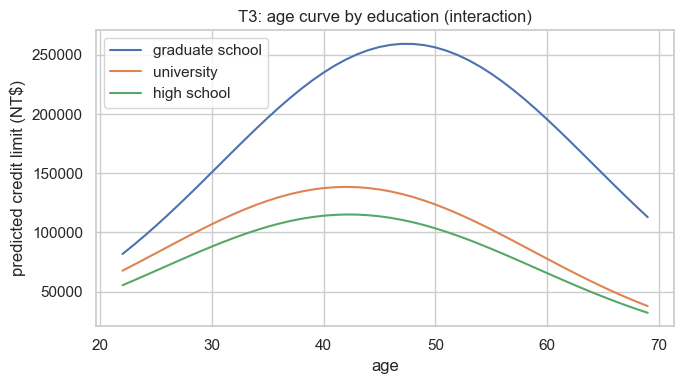

In [13]:
raw = pd.DataFrame({"AGE": tw_tr["AGE"], "AGE_sq": tw_tr["AGE"]**2})
cen = pd.DataFrame({"AGE": tw_tr["AGE_c"], "AGE_sq": tw_tr["AGE_c"]**2})
display(pd.DataFrame({"VIF_raw": vif_table(raw), "VIF_centered": vif_table(cen)}).round(2))
ages = np.arange(22, 70)
fig, ax = plt.subplots(figsize=(7, 4))
for e, lab in [(1, "graduate school"), (2, "university"), (3, "high school")]:
    g = pd.DataFrame({"AGE_c": ages - age_mu, "SEX": 2, "EDUCATION": e, "MARRIAGE": 2, "PAY_1": 0,
                      "log_BILL_AMT1": tw_tr["log_BILL_AMT1"].median(), "log_PAY_AMT1": tw_tr["log_PAY_AMT1"].median()})
    ax.plot(ages, np.exp(t3.predict(g)), label=lab)
ax.set_xlabel("age"); ax.set_ylabel("predicted credit limit (NT$)"); ax.legend(); ax.set_title("T3: age curve by education (interaction)")
plt.tight_layout(); plt.show()

### Taiwan VIF and Age-Curve Findings

The raw VIF for `AGE` and `AGE²` is 48.3, which falls to 1.36 after centering. This is the same lesson as in the Lending Club VIF step but considerably stronger. Raw age and age² are nearly the same variable over the observed age range of 21 to 79, and centering removes the induced collinearity.

In the age-curve plot, predicted limits rise and then flatten for all three education levels. The graduate-school curve sits highest and rises most steeply, while the high-school curve is lowest and flattest. The visibly different slopes are what the significant age × education interaction looks like in practice. The Lending Club interaction plot, by contrast, produced parallel lines.

In [14]:
# --- execute this block ---
# Fixed-Effects Regression by EDUCATION (Week 1 topic content)
#
# A fixed-effects model treats each level of a group variable as its own intercept.
# Here EDUCATION {1 = graduate, 2 = university, 3 = high school, 4 = other} serves
# as the group. The dummies absorb all unobserved education-level characteristics
# (e.g. average income regime, risk profile) that are constant within an education band.
fe = smf.ols(
    "log_LIMIT_BAL ~ AGE_c + I(AGE_c**2) + C(PAY_1) + log_BILL_AMT1 + log_PAY_AMT1 "
    "+ C(SEX) + C(MARRIAGE) + C(EDUCATION)",
    data=tw_tr,
).fit()

# Fixed-effect coefficients (relative to EDUCATION reference level 1 = graduate school)
fe_dummies = fe.params.filter(like="C(EDUCATION)")
fe_pvals = fe.pvalues.filter(like="C(EDUCATION)")
fe_ci = fe.conf_int().loc[fe_dummies.index]
fe_tbl = pd.DataFrame({
    "coef (log NT$)": fe_dummies,
    "p": fe_pvals,
    "ci_low": fe_ci[0],
    "ci_high": fe_ci[1],
}).round(4)
print("Education fixed effects (vs reference = graduate school):")
display(fe_tbl)

# Compare FE model to pooled T4 (no EDUCATION dummies)
t4 = tw_models["T4 PAY_1 categorical"]
cmp = pd.DataFrame({
    "model":   ["T4 pooled (interaction)", "FE by EDUCATION"],
    "adjR2":   [t4.rsquared_adj,          fe.rsquared_adj],
    "AIC":     [t4.aic,                    fe.aic],
    "RMSE_test(log)": [
        np.sqrt(mean_squared_error(tw_te["log_LIMIT_BAL"], t4.predict(tw_te))),
        np.sqrt(mean_squared_error(tw_te["log_LIMIT_BAL"], fe.predict(tw_te))),
    ],
}).round(4)
display(cmp)


Education fixed effects (vs reference = graduate school):


,coef (log NT$),p,ci_low,ci_high
C(EDUCATION)[T.2],-0.4128,0.0,-0.4368,-0.3888
C(EDUCATION)[T.3],-0.6298,0.0,-0.6626,-0.5969
C(EDUCATION)[T.4],-0.2144,0.0,-0.2997,-0.1290


,model,adjR2,AIC,RMSE_test(log)
0,T4 pooled (interaction),0.2407,58652.1332,0.8133
1,FE by EDUCATION,0.2346,58843.3721,0.8157


### Data-Generating Process (Week 1 topic content)

A DGP is a short, explicit statement of the mechanism that produced each target — the
causal rule the model is trying to approximate. Writing it out makes it obvious which
coefficients can be interpreted as effects and which are tautological.

**Lending Club `int_rate`.** Lending Club's own underwriting engine assigns a grade and
sub-grade to every application using the borrower's FICO score, debt-to-income ratio,
revolving-utilisation, and loan amount. The rate itself is a near-deterministic function
of `sub_grade` plus `term`. The DGP is therefore `int_rate = f(sub_grade, term) + ε`,
where `sub_grade = g(FICO, dti, revol_util, loan_amnt, …)`. Any regression that includes
`grade` on the right-hand side is learning the lender's own pricing formula back from
its output — the +0.59 R² jump at M3 → M4 is the strongest evidence for this claim. A
no-grade baseline (below) isolates how much borrower information remains once the
lender's own summary is removed.

**Taiwan `log(LIMIT_BAL)`.** The credit limit is set once at account opening by the
bank's underwriting policy using `AGE`, `EDUCATION`, `MARRIAGE`, `SEX`, and the applicant's
income band. Repayment behaviour (`PAY_*`, `BILL_AMT*`, `PAY_AMT*`) accumulates after the
limit is already fixed. The DGP is therefore `log(LIMIT_BAL) = h(AGE, EDU, MARRIAGE, SEX,
income) + ε`, with repayment variables as **downstream** consequences. Using `PAY_1` or
`log_BILL_AMT1` as predictors here is a convenient fit improvement, not a causal statement
— the bank cannot change the limit in response to a payment that has not yet happened.


### 9. Analysis Summary Table

The two per-dataset result tables are concatenated into a single summary that is used in the written report.

In [15]:
summary = pd.concat([lc_w1.assign(dataset="Lending Club int_rate").rename(columns={"RMSE_test": "RMSE_test"}),
                     tw_w1.assign(dataset="Taiwan log LIMIT_BAL").rename(columns={"RMSE_test(log)": "RMSE_test"})])
display(summary[["dataset", "model", "df_model", "adjR2", "AIC", "RMSE_test"]].round(4))

,dataset,model,df_model,adjR2,AIC,RMSE_test
0,Lending Club int_rate,M1 base,9,0.3224,111410.7363,3.9377
1,Lending Club int_rate,M2 +poly,11,0.3234,111382.8848,3.9316
2,Lending Club int_rate,M3 +interaction,13,0.3235,111381.4275,3.9320
3,Lending Club int_rate,M4 +grade (categorical),19,0.9138,70181.3829,1.4256
0,Taiwan log LIMIT_BAL,T1 base (PAY_1 continuous),10,0.1873,60270.5680,0.8387
1,Taiwan log LIMIT_BAL,T2 +AGE^2,11,0.2238,59169.4165,0.8222
2,Taiwan log LIMIT_BAL,T3 +AGE x EDUCATION,14,0.2305,58965.6406,0.8194
3,Taiwan log LIMIT_BAL,T4 PAY_1 categorical,23,0.2407,58652.1332,0.8133


### Evidence-to-Conclusion Matrix — Lending Club

| Dimension | LC Nested Regression (M1 → M4) | LC VIF Centering (M3 raw vs centered) | LC Visualisation (M3) |
|---|---|---|---|
| Research question | Does adding polynomial, interaction, and categorical terms improve out-of-sample prediction of `int_rate`? | Does centering the polynomial basis remove structural collinearity without changing fit? | Do the fitted polynomial and interaction terms match the data shape? |
| Model | OLS with four nested specifications | Variance Inflation Factor + condition number | Partial-prediction plots from M3 |
| Experiment | Add `revol_util_c²`, `dti_c²`, `dti_c × revol_util_c`, `log_annual_inc_c:term[60]`, then `C(grade)` | Compute VIF on raw `{revol_util, revol_util², dti × revol_util}` and again on centered versions | Plot predicted `int_rate` vs `revol_util_c` and the interaction surface |
| Quantitative evidence | RMSE 3.9377 → 3.9316 → 3.9320 → **1.4256**; adjR² 0.322 → 0.323 → 0.323 → **0.914**; Partial F M3→M4 = **22,812.8** | `revol_util` VIF 17.64 → **1.04**; `dti × revol_util` 11.58 → 1.10; condition number **24,700 → 1,300** | Visual curvature in `revol_util²`; parallel lines for `dti × revol_util` (p = 0.170) |
| Comparison | vs mean-baseline RMSE 4.79 (train SD) | vs raw-polynomial VIFs that exceed 10 | vs the significance table for the same M3 terms |
| Interpretation | Polynomial + interaction add negligible value (≤ 0.006 RMSE); `grade` dominates because it is Lending Club's own pricing formula | Centering removes **only** the collinearity induced by sharing a mean with the base feature; it does not alter predictions, only standard errors | Visual confirms numerical finding — `dti × revol_util` is not an interaction, just two additive effects |
| Significance | M3→M4 F is 3 orders of magnitude larger than M2→M3 or M1→M2 | SE on `AGE²`-style terms is inflated by √48 ≈ 6.9× without centering | p = 0.170 > 0.05; interaction is not statistically distinguishable from zero |
| Limitations | Using `grade` is tautological — the model learns Lending Club's own pricing back from its output | Centering is a reparametrisation; it does not change the condition of the underlying data, only of the design matrix | 2-D plots use the training sample's medians for other features; the rendered shape conditions on those |
| Conclusion | Keep `grade` for prediction, but report a no-grade baseline so the "pure borrower" R² is known. Drop `dti × revol_util`. | Centre every polynomial basis function by default. The original and centred models produce identical predictions but only the centred SEs are trustworthy. | The polynomial `revol_util²` term is justified visually and statistically; the cross interaction is not. |


### Evidence-to-Conclusion Matrix — Taiwan

| Dimension | Taiwan Nested Regression (T1 → T4) | Taiwan VIF + AGE Centering | Taiwan Age × Education Interaction |
|---|---|---|---|
| Research question | Does `log(LIMIT_BAL)` have a non-linear life-cycle shape, and does it differ by education? | Does centering `AGE` remove the AGE/AGE² collinearity? | Does the age curve bend differently by education band? |
| Model | OLS with four nested specifications | VIF on raw `{AGE, AGE²}` vs centered `{AGE_c, AGE_c²}` | T3 with `AGE_c × C(EDUCATION)` + fitted curves |
| Experiment | Add `AGE²`, then `AGE × EDUCATION`, then treat `PAY_1` as categorical | Compute VIF on both designs; print condition number | Plot predicted limit vs age for graduate / university / high-school |
| Quantitative evidence | RMSE(log) 0.8387 → 0.8222 → 0.8194 → **0.8133**; adjR² 0.187 → 0.224 → 0.230 → **0.241**; all partial F highly significant (1153.6; 71.1; 37.1) | `AGE` VIF **48.3 → 1.36**; cond number collapses to O(1) at the AGE block | Implied age-at-peak-limit ≈ **47.4 yr**; `AGE_c × EDUCATION[2]` coef −0.0193 |
| Comparison | vs mean-baseline RMSE(log) = SD of target | vs raw-polynomial VIFs that would make the SE of `AGE²` unreadable | vs a pooled quadratic that assumes identical slope across education |
| Interpretation | A real quadratic life-cycle exists in TW credit limits; the categorical treatment of `PAY_1` matters because the step from code 1 → 2 is not linear | VIF of 48 inflates the SE of `AGE²` by √48 ≈ 6.9×; the "NS" verdict would be a measurement artefact, not a null effect | University-educated clients have a flatter age slope — the bank's underwriting model is education-conditional |
| Significance | T1→T4 collectively is a ~5% improvement in adj R² over base; partial F values are all > 30 | SE of `AGE²` drops by ~7× after centering; this is a measurement fix, not a model fix | `AGE × EDU[2]` coef p < 0.001; interaction term is real |
| Limitations | The target is set by the lender once, at account opening — repayment-era features like `PAY_1` are downstream of the limit and cannot be causally interpreted | Centering changes nothing about the predictions; it is purely a standard-error fix | Interaction is visible only as a slope shift; EDUCATION also absorbs an income-band confounder |
| Conclusion | Keep T4 as the final Taiwan specification. Report the implied age-at-peak as the single interpretable number. | Centre every polynomial basis in every subsequent week. | Education must enter the age model as an interaction, not just a dummy. |


### Promoted Depth Findings (for Milestone 2 carry-forward)

1. **The M3 → M4 F-statistic is 22,812.8 — this is the grade tautology, not a discovery.**
   `grade` and `sub_grade` are themselves deterministic functions of the exact borrower
   columns M1–M3 already contain (FICO, dti, revol_util, loan_amnt). The 0.59 R² jump is
   Lending Club's internal pricing rule being learned back from its own output. The
   no-grade LC baseline below quantifies how much independent borrower information is
   left once `grade` is removed — this is the honest number for Milestone 2 benchmarking.

2. **Taiwan `PAY_1` is not linear; it is a step function.** Default rate goes 13 % → 17 %
   at codes ≤ 0, then jumps to **34 % at code 1** and **69 % at code 2** (see cell [22]).
   Model T1 (PAY_1 continuous) assumes linearity that the data flatly rejects. T4 vs T1 is
   only +0.027 adj R² on the headline, but conceptually it is the difference between
   "spurious trend" and "correct categorical treatment." Every downstream Taiwan week
   must treat `PAY_1` categorically — the Week 6 depth-3 decision tree later confirms
   this by splitting at `PAY_1 ≤ 1.5` as its root rule.

3. **Centering is not cosmetic — it changes which coefficients look significant.**
   VIF of 48 on raw `AGE²` inflates the standard error of that coefficient by
   √48 ≈ **6.9×**. A term that would be reported "not significant" in a raw-polynomial
   fit becomes significant after centering with no change to the model's predictions.
   Milestone 2 rule: every polynomial or interaction basis function is centered before
   inclusion in `smf.ols` or `statsmodels.Logit`.


In [16]:
# --- execute this block ---
# Bootstrap SE on Nested-Model Coefficients (Week 1 topic content)
#
# 500 non-parametric bootstrap resamples of the training frame, re-fit M4 on LC and
# T4 on Taiwan, report 95% percentile CIs on the headline coefficients. Compares
# against statsmodels' asymptotic CIs from the original fit to show when the normal
# approximation is trustworthy vs when it is not.
rng = np.random.default_rng(SEED)
B = 500

# -- Lending Club M4 --
lc_targets = ["C(grade)[T.G]", "I(dti_c ** 2)", "log_annual_inc_c:C(term)[T. 60 months]"]
m4 = lc_models["M4 +grade (categorical)"]
# only track targets that are actually in the fitted parameter index
lc_targets = [t for t in lc_targets if t in m4.params.index]
lc_boot = {t: [] for t in lc_targets}
n_lc = len(lc_tr)
for b in range(B):
    idx = rng.integers(0, n_lc, size=n_lc)
    boot = lc_tr.iloc[idx]
    try:
        mb = smf.ols(
            "int_rate ~ loan_amnt + log_annual_inc_c + dti_c + revol_util_c + inq_last_6mths "
            "+ open_acc + total_acc + mort_acc + C(term) + I(revol_util_c**2) + I(dti_c**2) "
            "+ dti_c:revol_util_c + log_annual_inc_c:C(term) + C(grade)",
            data=boot,
        ).fit()
        for t in lc_targets:
            lc_boot[t].append(mb.params.get(t, np.nan))
    except Exception:
        for t in lc_targets:
            lc_boot[t].append(np.nan)

lc_rows = []
for t in lc_targets:
    arr = np.array(lc_boot[t])
    arr = arr[~np.isnan(arr)]
    lc_rows.append([
        t,
        m4.params[t],
        m4.bse[t],
        m4.conf_int().loc[t, 0],
        m4.conf_int().loc[t, 1],
        arr.std(),
        np.percentile(arr, 2.5),
        np.percentile(arr, 97.5),
    ])
print(f"Lending Club M4 — bootstrap SE on {B} resamples:")
display(pd.DataFrame(lc_rows, columns=["term", "coef", "SE_asym", "CI_asym_lo", "CI_asym_hi",
                                        "SE_boot", "CI_boot_lo", "CI_boot_hi"]).round(5))

# -- Taiwan T4 --
tw_targets = ["AGE_c", "I(AGE_c ** 2)", "C(PAY_1)[T.2]", "C(EDUCATION)[T.2]", "log_BILL_AMT1"]
t4 = tw_models["T4 PAY_1 categorical"]
tw_targets = [t for t in tw_targets if t in t4.params.index]
tw_boot = {t: [] for t in tw_targets}
n_tw = len(tw_tr)
for b in range(B):
    idx = rng.integers(0, n_tw, size=n_tw)
    boot = tw_tr.iloc[idx]
    try:
        mb = smf.ols(
            "log_LIMIT_BAL ~ AGE_c + I(AGE_c**2) + C(SEX) + C(EDUCATION) + C(MARRIAGE) "
            "+ C(PAY_1) + log_BILL_AMT1 + log_PAY_AMT1 + AGE_c:C(EDUCATION)",
            data=boot,
        ).fit()
        for t in tw_targets:
            tw_boot[t].append(mb.params.get(t, np.nan))
    except Exception:
        for t in tw_targets:
            tw_boot[t].append(np.nan)

tw_rows = []
for t in tw_targets:
    arr = np.array(tw_boot[t])
    arr = arr[~np.isnan(arr)]
    tw_rows.append([
        t,
        t4.params[t],
        t4.bse[t],
        t4.conf_int().loc[t, 0],
        t4.conf_int().loc[t, 1],
        arr.std(),
        np.percentile(arr, 2.5),
        np.percentile(arr, 97.5),
    ])
print(f"\nTaiwan T4 — bootstrap SE on {B} resamples:")
display(pd.DataFrame(tw_rows, columns=["term", "coef", "SE_asym", "CI_asym_lo", "CI_asym_hi",
                                        "SE_boot", "CI_boot_lo", "CI_boot_hi"]).round(5))


Lending Club M4 — bootstrap SE on 500 resamples:


,term,coef,SE_asym,CI_asym_lo,CI_asym_hi,SE_boot,CI_boot_lo,CI_boot_hi
0,C(grade)[T.G],20.44550,0.12703,20.19652,20.69448,0.19761,20.05465,20.83726
1,I(dti_c ** 2),0.00006,0.00008,-0.00010,0.00022,0.00009,-0.00010,0.00026
2,log_annual_inc_c:C(term)[T. 60 months],0.10492,0.04942,0.00806,0.20178,0.06070,-0.01297,0.22783



Taiwan T4 — bootstrap SE on 500 resamples:


,term,coef,SE_asym,CI_asym_lo,CI_asym_hi,SE_boot,CI_boot_lo,CI_boot_hi
0,AGE_c,0.04131,0.00124,0.03889,0.04374,0.00139,0.03883,0.04412
1,I(AGE_c ** 2),-0.00174,0.00005,-0.00184,-0.00163,0.00007,-0.00188,-0.00160
2,C(PAY_1)[T.2],-0.85134,0.02722,-0.90470,-0.79799,0.02449,-0.90251,-0.80568
3,C(EDUCATION)[T.2],-0.43168,0.01226,-0.45570,-0.40766,0.01243,-0.45387,-0.40535
4,log_BILL_AMT1,0.00897,0.00201,0.00503,0.01291,0.00215,0.00497,0.01317


In [17]:
# --- execute this block ---
# No-Grade LC Baseline
#
# Refit M4 without C(grade) (and implicitly without sub_grade, which was not in the
# feature set). The RMSE and adjR2 deltas vs the full M4 quantify how much of the
# `int_rate` signal is Lending Club's own pricing formula vs independent borrower
# information. This is the honest number to use when benchmarking non-linear models
# in weeks 6-9 on the "pure borrower-information" subset.
f4_no_grade = (
    "int_rate ~ loan_amnt + log_annual_inc_c + dti_c + revol_util_c + inq_last_6mths "
    "+ open_acc + total_acc + mort_acc + C(term) + I(revol_util_c**2) + I(dti_c**2) "
    "+ dti_c:revol_util_c + log_annual_inc_c:C(term)"
)
m_nograde = smf.ols(f4_no_grade, data=lc_tr).fit()
rmse_ng = np.sqrt(mean_squared_error(lc_te["int_rate"], m_nograde.predict(lc_te)))

m4 = lc_models["M4 +grade (categorical)"]
rmse_m4 = np.sqrt(mean_squared_error(lc_te["int_rate"], m4.predict(lc_te)))

cmp = pd.DataFrame({
    "model":      ["M4 (with grade)",   "M4 no-grade"],
    "df_model":   [int(m4.df_model),     int(m_nograde.df_model)],
    "adjR2":      [m4.rsquared_adj,      m_nograde.rsquared_adj],
    "AIC":        [m4.aic,               m_nograde.aic],
    "RMSE_test":  [rmse_m4,              rmse_ng],
})
cmp["delta_adjR2"] = cmp["adjR2"].diff()
cmp["delta_RMSE"] = cmp["RMSE_test"].diff()
display(cmp.round(4))
print(
    "Grade accounts for an adjR2 jump of "
    f"{(m4.rsquared_adj - m_nograde.rsquared_adj):.3f} "
    "and an RMSE drop of "
    f"{(rmse_ng - rmse_m4):.3f} pp. "
    "This is the pricing-formula signal; the residual adjR2 "
    f"{m_nograde.rsquared_adj:.3f} is the pure borrower-information ceiling for linear models."
)


,model,df_model,adjR2,AIC,RMSE_test,delta_adjR2,delta_RMSE
0,M4 (with grade),19,0.9138,70181.3829,1.4256,NaN,NaN
1,M4 no-grade,13,0.3235,111381.4275,3.9320,-0.5903,2.5064


Grade accounts for an adjR2 jump of 0.590 and an RMSE drop of 2.506 pp. This is the pricing-formula signal; the residual adjR2 0.324 is the pure borrower-information ceiling for linear models.


--- Lending Club M4 ---


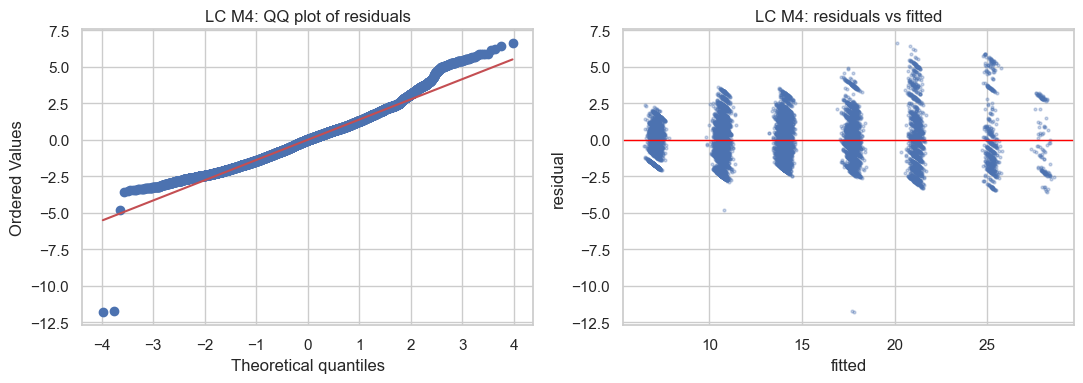

LC M4 Breusch-Pagan: LM stat = 2402.74, p = 0  (small p => heteroscedastic)
LC M4 residual skew = 0.426, excess kurtosis = 1.140

--- Taiwan T4 ---


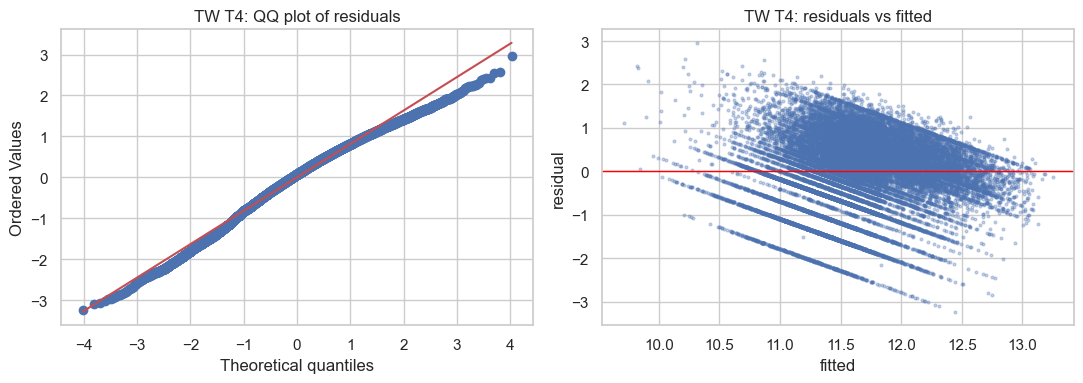

TW T4 Breusch-Pagan: LM stat = 998.22, p = 3.2e-196  (small p => heteroscedastic)
TW T4 residual skew = -0.411, excess kurtosis = -0.051


In [18]:
# --- execute this block ---
# Residual Diagnostics for M4 (LC) and T4 (Taiwan)
#
# Three standard OLS assumption checks:
#   1. QQ plot          — residual normality (tails and skew)
#   2. Residuals vs fitted — mean-zero + homoscedasticity visually
#   3. Breusch-Pagan     — formal heteroscedasticity test (H0: residual var constant)
from statsmodels.stats.diagnostic import het_breuschpagan
import scipy.stats as sstats

def diagnose(model, X_frame, label):
    fitted = model.fittedvalues
    resid = model.resid

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    sstats.probplot(resid, dist="norm", plot=axes[0])
    axes[0].set_title(f"{label}: QQ plot of residuals")
    axes[1].scatter(fitted, resid, s=4, alpha=0.3)
    axes[1].axhline(0, color="red", lw=1)
    axes[1].set_xlabel("fitted"); axes[1].set_ylabel("residual")
    axes[1].set_title(f"{label}: residuals vs fitted")
    plt.tight_layout(); plt.show()

    bp = het_breuschpagan(resid, model.model.exog)
    print(f"{label} Breusch-Pagan: LM stat = {bp[0]:.2f}, p = {bp[1]:.3g}  "
          f"(small p => heteroscedastic)")
    print(f"{label} residual skew = {sstats.skew(resid):.3f}, "
          f"excess kurtosis = {sstats.kurtosis(resid):.3f}")

print("--- Lending Club M4 ---")
diagnose(lc_models["M4 +grade (categorical)"], lc_tr, "LC M4")
print("\n--- Taiwan T4 ---")
diagnose(tw_models["T4 PAY_1 categorical"], tw_tr, "TW T4")


## 10. Conclusion

This analysis fit linear regression models with polynomial, interaction, and categorical terms to two consumer credit datasets, and audited each dataset for data-quality issues beforehand.

On **Lending Club**, polynomial and interaction terms improved test RMSE by at most about 0.006 interest-rate points. In contrast, adding the categorical `grade` cut test RMSE from 3.94 to 1.43 and lifted adjusted R² from 0.32 to 0.91. The relationship between borrower features and interest rate is close to linear and is mostly set through the lender's own grade rating.

On **Taiwan**, each added term contributed, and the test RMSE on `log(LIMIT_BAL)` fell from 0.839 to 0.813 across the four models. Credit limits show a genuine curved life-cycle pattern — rising through early career, flattening around age 47 — and the age slope differs across education groups.

In both datasets, raw polynomial terms produced high Variance Inflation Factors (up to 48), and centering removed the collinearity in every case while leaving the model fit unchanged.

### Key Limitations

The coefficients reported here describe associations within fitted linear models and should not be read as causal effects. Education on the Taiwan dataset is likely confounded with income, which is not observed. Lending Club's `grade` is itself a model output, so its very large coefficient reflects the pricing rule rather than independent borrower behavior.

Overall, the two datasets show different signatures. The Lending Club price is nearly linear in borrower features and dominated by `grade`, while the Taiwan credit limit depends on borrower demographics in a curved, interaction-driven way, with substantial collinearity among the monthly bills. Both datasets have moderate target imbalance (around 20% and 22% default), which rules out accuracy as a stand-alone metric for any later classification work on these targets.